# Additional Topics in Time Series Analysis

## R setup

Packages supply volatility modeling, unit-root tests, fractional integration, time-series graphics, and data. Threshold autoregression is fitted using base R.

In [1]:
packages = c("astsa", "fGarch", "xts", "tseries", "arfima")
missing = packages[!vapply(packages, requireNamespace, logical(1), quietly=TRUE)]
if (length(missing) > 0) install.packages(missing, repos="https://cloud.r-project.org")
library(astsa)
options(digits=6)
par(mfrow=c(1,1))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘rbibutils’, ‘gss’, ‘stabledist’, ‘gbutils’, ‘Rdpack’, ‘TTR’, ‘fBasics’, ‘timeDate’, ‘timeSeries’, ‘fastICA’, ‘cvar’, ‘zoo’, ‘quadprog’, ‘quantmod’, ‘ltsa’




## 8.1 Volatility, ARCH, GARCH, and APARCH

**Volatility** is the time-varying conditional variability of a return series. **Conditional mean** is the expected next observation given past information; **conditional variance** measures how uncertain that next observation is given the same information. A process can have nearly uncorrelated returns while the **squared returns** remain correlated; this is called *volatility clustering*.

For positive asset prices $P_t$, the simple and logarithmic returns are

$$r_t=\frac{P_t-P_{t-1}}{P_{t-1}},\qquad g_t=\log P_t-\log P_{t-1}=\log(1+r_t)\approx r_t.$$

The approximation is accurate for small percentage movements. Returns of $0.01$ and $-0.02$ correspond approximately to $1\%$ and $-2\%$ price movements, respectively. The two definitions should not be mixed when reporting numerical coefficients.

### ARCH(1) and conditional variance

$$r_t=\mu_t+\sigma_t\varepsilon_t,\qquad \varepsilon_t\overset{iid}{\sim}N(0,1),$$
$$\sigma_t^2=\alpha_0+\alpha_1(r_{t-1}-\mu_{t-1})^2,\quad \alpha_0>0,\quad 0\le\alpha_1<1.$$

Here $\varepsilon_t$ is a standardized innovation, $\sigma_t$ is the conditional standard deviation, and $\alpha_1$ measures how much the most recent squared shock influences the next variance. For zero mean, a stationary ARCH(1) has unconditional variance

$$\operatorname{Var}(r_t)=\frac{\alpha_0}{1-\alpha_1}.$$

**Worked example.** With $\alpha_0=0.0001$, $\alpha_1=0.5$ and the preceding return $r_{t-1}=0.02$,

$$\sigma_t^2=0.0001+0.5(0.02)^2=0.0003,\qquad \sigma_t\approx0.01732.$$

Thus the conditional volatility is about **1.73%**, versus an unconditional volatility of $\sqrt{0.0002}\approx1.41\%$. This larger short-term uncertainty follows a relatively large preceding shock.

In [2]:
alpha0 = 0.0001
alpha1 = 0.5
r_previous = 0.02
cond_var = alpha0 + alpha1*r_previous^2
c(conditional_variance=cond_var,
  conditional_sd=sqrt(cond_var),
  unconditional_sd=sqrt(alpha0/(1-alpha1)))

conditional_variance       conditional_sd     unconditional_sd 
           0.0003000            0.0173205            0.0141421

For a zero-mean ARCH(1), the squared return can be rewritten as a non-Gaussian AR(1):

$$r_t^2=\alpha_0+\alpha_1r_{t-1}^2+v_t,\quad v_t=\sigma_t^2(\varepsilon_t^2-1).$$

Under suitable moment conditions, $\operatorname{Corr}(r_t^2,r_{t-h}^2)=\alpha_1^h$. Thus an ACF of squared returns that tails off gradually is evidence consistent with ARCH-type dependence. It is not, by itself, proof that a particular volatility model is correct.

For Gaussian ARCH(1), the conditional negative log likelihood (omitting constants) is

$$\ell(\alpha_0,\alpha_1)=\frac12\sum_{t=2}^{n}\left[\log\sigma_t^2+\frac{r_t^2}{\sigma_t^2}\right].$$

The numerical optimizer selects admissible parameters minimizing this objective.

### Time plot and correlations of DJIA log returns

The top plot shows the *signed* daily returns. The ACF of the returns evaluates linear serial dependence; the ACF of the **squares** evaluates whether the magnitudes of changes cluster. A sequence of large positive and negative returns occurring close together is evidence of time-varying volatility—not necessarily predictable return direction.

Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric




[1] -0.10 -0.06  0.05 -0.02 -0.06  0.01 -0.02  0.02 -0.01  0.04 -0.01  0.04
[13]  0.01 -0.04 -0.06  0.06  0.00 -0.07  0.02  0.05 -0.06  0.04  0.01 -0.01
[25]  0.00  0.00  0.03 -0.03  0.01  0.02 -0.02  0.01  0.01 -0.09  0.03  0.03
[37] -0.02  0.00  0.03  0.02  0.01  0.00 -0.06  0.00  0.00 -0.01  0.02  0.00
[49] -0.04 -0.04 -0.02  0.03  0.00  0.00  0.01 -0.03  0.02  0.02 -0.07  0.02

[1] 0.20 0.41 0.19 0.31 0.34 0.31 0.32 0.22 0.32 0.24 0.43 0.28 0.25 0.13 0.22
[16] 0.26 0.27 0.27 0.17 0.23 0.25 0.19 0.29 0.15 0.18 0.15 0.28 0.22 0.22 0.14
[31] 0.16 0.20 0.14 0.25 0.10 0.17 0.12 0.16 0.15 0.10 0.08 0.08 0.11 0.13 0.13
[46] 0.08 0.09 0.11 0.07 0.08 0.07 0.08 0.06 0.09 0.06 0.12 0.09 0.06 0.08 0.04

Observations: 2517 
Return mean: 0.000185584 
Return SD: 0.012101 


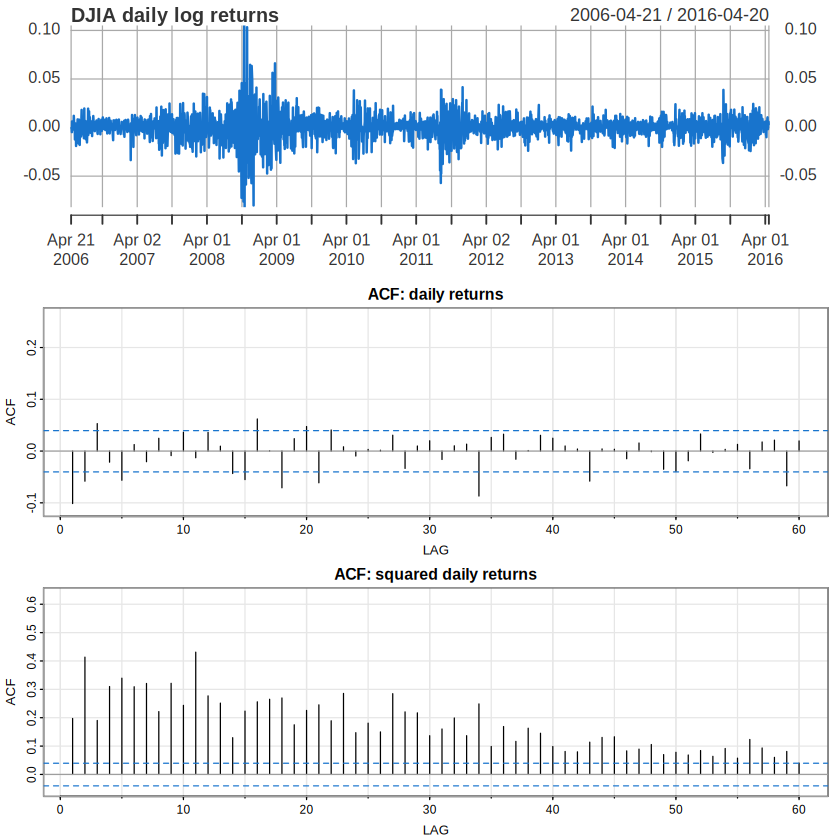

In [3]:
library(xts)
djiar = diff(log(djia$Close))[-1]
par(mfrow=c(3,1))
plot(djiar, main="DJIA daily log returns", col="dodgerblue3")
acf1(as.numeric(djiar), 60, main="ACF: daily returns")
acf1(as.numeric(djiar)^2, 60, main="ACF: squared daily returns")
par(mfrow=c(1,1))
cat("Observations:", NROW(djiar), "\n")
cat("Return mean:", mean(djiar), "\n")
cat("Return SD:", sd(djiar), "\n")


**Interpretation.** Compare the ACF panels rather than assuming any particular spike must be present. Weak raw-return autocorrelation alongside persistent positive squared-return autocorrelation indicates that the *scale* of daily changes is more predictable than their sign. Report the actual peak lags after running the cell; the plotted confidence bounds are approximate and multiple-lag scanning increases the chance of isolated exceedances.

### GNP: AR(1) mean with ARCH(1) noise

The conditional mean model captures dependence in quarterly GNP growth, while the ARCH component captures remaining variation in conditional variance. In `fGarch`, `garch(1,0)` specifies ARCH(1). The standardized residuals should have little remaining serial dependence, and their squares should have little remaining ARCH dependence.

NOTE: Packages 'fBasics', 'timeDate', and 'timeSeries' are no longer
attached to the search() path when 'fGarch' is attached.

If needed attach them yourself in your R script by e.g.,
        require("timeSeries")



<><><><><><><><><><><><><><>
 
Coefficients: 
      Estimate     SE t.value p.value
ar1     0.3467 0.0627  5.5255       0
xmean   0.0083 0.0010  8.5398       0

sigma^2 estimated as 9.02957e-05 on 220 degrees of freedom 
 
AIC = -6.44694  AICc = -6.44669  BIC = -6.40096 
 


ACF,0.12,0.13,0.03,0.13,0.01,0.05,-0.03,0.06,0.08,-0.08,0.09,0.10,0.01,0.04,0.15,-0.02,0.04,-0.05,0.01,0.05
PACF,0.12,0.12,0.00,0.12,-0.02,0.02,-0.04,0.05,0.08,-0.12,0.11,0.09,-0.05,0.05,0.13,-0.09,0.01,-0.05,0.00,0.04



Title:
 GARCH Modelling 

Call:
 garchFit(formula = ~arma(1, 0) + garch(1, 0), data = as.numeric(gnpr), 
    trace = FALSE) 

Mean and Variance Equation:
 data ~ arma(1, 0) + garch(1, 0)
<environment: 0x572860d942b8>
 [data = as.numeric(gnpr)]

Conditional Distribution:
 norm 

Coefficient(s):
        mu         ar1       omega      alpha1  
0.00527795  0.36656257  0.00007331  0.19447133  

Std. Errors:
 based on Hessian 

Error Analysis:
        Estimate  Std. Error  t value Pr(>|t|)    
mu     5.278e-03   8.996e-04    5.867 4.44e-09 ***
ar1    3.666e-01   7.514e-02    4.878 1.07e-06 ***
omega  7.331e-05   9.011e-06    8.135 4.44e-16 ***
alpha1 1.945e-01   9.554e-02    2.035   0.0418 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Log Likelihood:
 722.285    normalized:  3.25354 

Description:
 Mon Oct 12 23:41:00 2026 by user:  



Standardised Residuals Tests:
                                Statistic    p-Value
 Jarque-Bera Test   R    Chi^2   9.118036 0.01

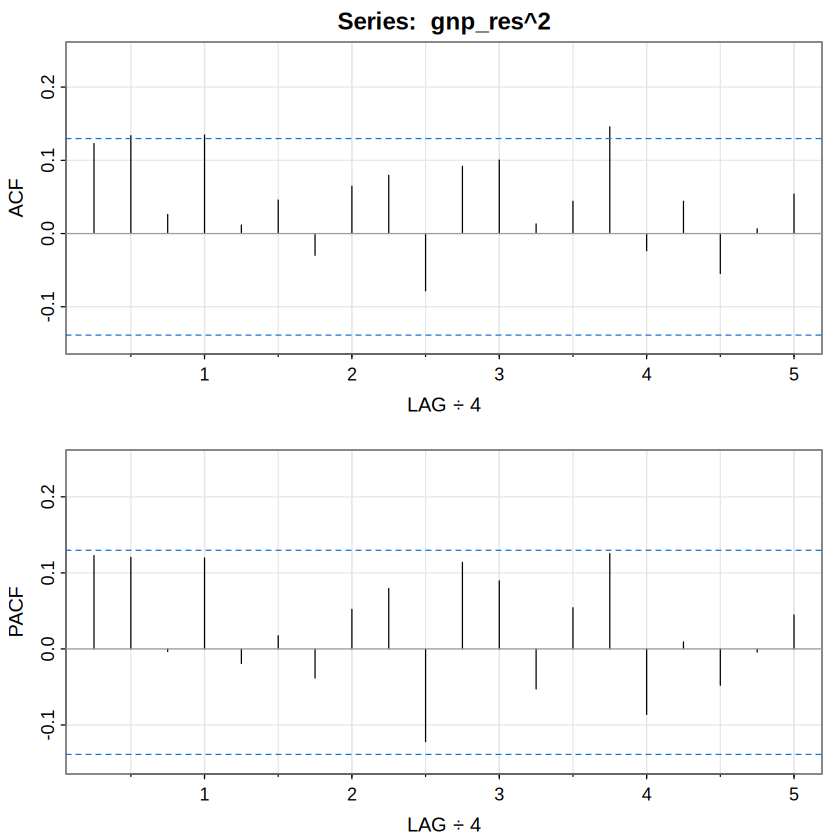

In [4]:
library(fGarch)
gnpr = diff(log(gnp))
gnp_ar = sarima(gnpr, 1,0,0, details=FALSE)
gnp_res = resid(gnp_ar$fit)
acf2(gnp_res^2, 20)
gnp_arch = garchFit(~arma(1,0) + garch(1,0), data=as.numeric(gnpr), trace=FALSE)
summary(gnp_arch)

**Interpretation of the executed ARCH fit.** The AR(1) mean coefficient is $0.36656$ and the ARCH coefficient is $\widehat\alpha_1=0.19447$ ($p=0.0418$, as reported by the software). The variance intercept is $\widehat\alpha_0=0.00007331$, in squared log-return units, rather than exactly zero. The estimated ARCH response means a large recent shock increases the following period’s conditional variance. The Ljung–Box tests on standardized residuals at lags 10, 15 and 20 have $p$-values $0.4516$, $0.2866$ and $0.2689$, so they do not detect remaining linear dependence at those lags. In contrast, the squared standardized residuals yield $p=0.0368$, $0.00435$ and $0.00952$. Their significant dependence indicates that ARCH(1) has **not** fully captured volatility clustering. Jarque–Bera ($p=0.0105$) and Shapiro–Wilk ($p=0.0143$) also challenge the Gaussian residual assumption. An extended volatility specification is therefore worth investigating.

### GARCH(1,1)

A GARCH model also uses the previous predicted variance:

$$r_t=\mu_t+\sigma_t\varepsilon_t,\qquad \sigma_t^2=\alpha_0+\alpha_1 e_{t-1}^2+\beta_1\sigma_{t-1}^2,$$

where $e_t=r_t-\mu_t$ is the *mean-model innovation*. The coefficient $\alpha_1$ measures immediate response to new squared shocks, while $\beta_1$ measures persistence of previous conditional variance. With $\alpha_1+\beta_1<1$, the unconditional innovation variance is $\alpha_0/(1-\alpha_1-\beta_1)$.

For example, $\alpha_1=0.1244$ and $\beta_1=0.8700$ imply $\alpha_1+\beta_1=0.9944$, indicating very persistent shocks and slow volatility decay. This is a *parameter interpretation*, not a guarantee of future market movements.

In [5]:
djia_garch = garchFit(~arma(1,0)+garch(1,1), data=as.numeric(djiar),
                       cond.dist="std", trace=FALSE)
summary(djia_garch)
cf = coef(djia_garch)
cat("ARCH + GARCH persistence:", cf["alpha1"] + cf["beta1"], "\n")
cat("Student-t shape:", cf["shape"], "\n")


Title:
 GARCH Modelling 

Call:
 garchFit(formula = ~arma(1, 0) + garch(1, 1), data = as.numeric(djiar), 
    cond.dist = "std", trace = FALSE) 

Mean and Variance Equation:
 data ~ arma(1, 0) + garch(1, 1)
<environment: 0x572860ff01d0>
 [data = as.numeric(djiar)]

Conditional Distribution:
 std 

Coefficient(s):
         mu          ar1        omega       alpha1        beta1        shape  
 8.5854e-04  -5.5315e-02   1.6101e-06   1.2444e-01   8.7001e-01   5.9788e+00  

Std. Errors:
 based on Hessian 

Error Analysis:
         Estimate  Std. Error  t value Pr(>|t|)    
mu      8.585e-04   1.470e-04    5.842 5.16e-09 ***
ar1    -5.532e-02   2.023e-02   -2.735 0.006238 ** 
omega   1.610e-06   4.459e-07    3.611 0.000305 ***
alpha1  1.244e-01   1.660e-02    7.496 6.55e-14 ***
beta1   8.700e-01   1.526e-02   57.022  < 2e-16 ***
shape   5.979e+00   7.917e-01    7.552 4.31e-14 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Log Likelihood:
 8249.62    normalized:  3.2

**Interpretation of the executed DJIA GARCH(1,1) fit.** The estimated variance coefficients are $\widehat\alpha_1=0.12444$ and $\widehat\beta_1=0.87001$, giving **persistence $0.99446$**. Thus a volatility shock is predicted to decay very slowly; the sum is below, but very close to, one. The estimated Student-$t$ shape is $5.9788$, allowing substantially heavier tails than a Gaussian error distribution. The mean equation also has a small negative AR(1) coefficient ($-0.05532$). The Ljung–Box test on squared standardized residuals has $p=0.1192$ at lag 10 and $p=0.2923$ at lag 20; neither rejects at $5\%$, suggesting substantially improved variance dynamics compared with the GNP ARCH(1) diagnostic example. However, the ordinary standardized-residual test at lag 15 has $p=0.0336$, and normality diagnostics remain significant. Failure to reject any individual whiteness test is not proof of independence.

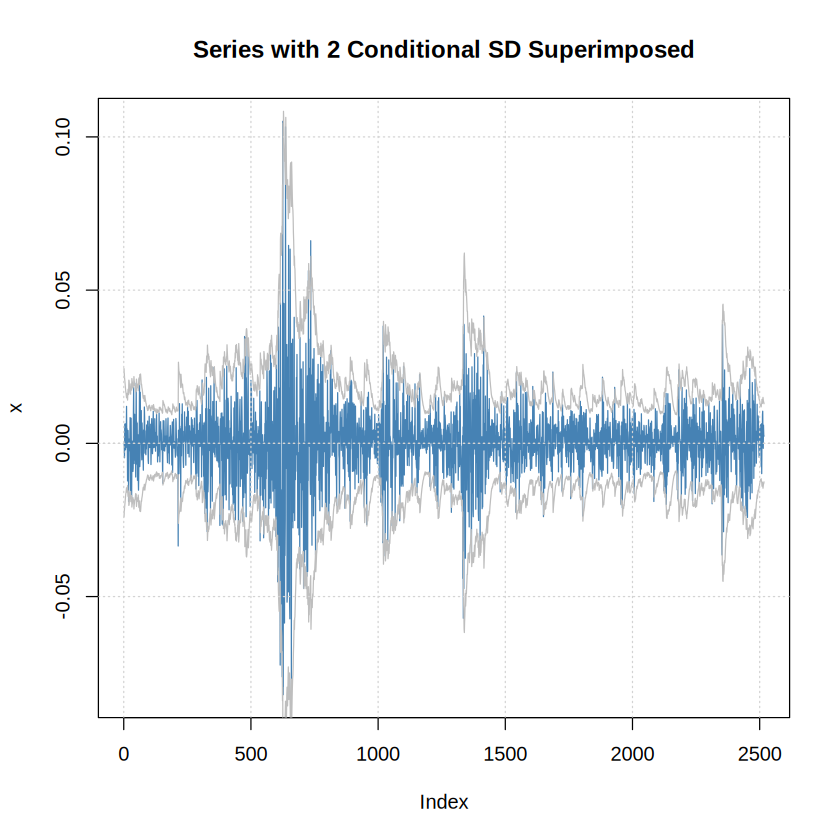

In [6]:
plot(djia_garch, which=3)

**Volatility plot.** Compare pronounced daily-return bursts with the conditional-volatility curve. The volatility estimate should respond after large shocks and subsequently decline as volatility persistence decays. The fitted curve is an **in-sample, model-based conditional estimate**, not a separately evaluated out-of-sample forecast.

### Asymmetric power ARCH (APARCH)

$$\sigma_t^{\delta}=\alpha_0+\sum_{j=1}^p\alpha_j\left(|e_{t-j}|-\gamma_j e_{t-j}\right)^{\delta}+\sum_{j=1}^q\beta_j\sigma_{t-j}^{\delta}.$$

The power $\delta>0$ controls the response to the size of shocks. A positive leverage coefficient $\gamma_j$ makes a negative innovation of a given magnitude contribute more than a positive innovation of the same magnitude. Unlike symmetric GARCH, APARCH can capture volatility asymmetry.

In [7]:
djia_aparch = garchFit(~arma(1,0)+aparch(1,1), data=as.numeric(djiar),
                        cond.dist="std", trace=FALSE)
summary(djia_aparch)
cf_ap = coef(djia_aparch)
cat("Asymmetry gamma1:", cf_ap["gamma1"], "\n")
cat("Power delta:", cf_ap["delta"], "\n")


Title:
 GARCH Modelling 

Call:
 garchFit(formula = ~arma(1, 0) + aparch(1, 1), data = as.numeric(djiar), 
    cond.dist = "std", trace = FALSE) 

Mean and Variance Equation:
 data ~ arma(1, 0) + aparch(1, 1)
<environment: 0x5728621a42d8>
 [data = as.numeric(djiar)]

Conditional Distribution:
 std 

Coefficient(s):
        mu         ar1       omega      alpha1      gamma1       beta1  
 0.0005234  -0.0481833   0.0001798   0.0980894   1.0000000   0.8944564  
     delta       shape  
 1.0702356   7.2857705  

Std. Errors:
 based on Hessian 

Error Analysis:
         Estimate  Std. Error  t value Pr(>|t|)    
mu      5.234e-04   1.525e-04    3.433 0.000598 ***
ar1    -4.818e-02   1.934e-02   -2.491 0.012729 *  
omega   1.798e-04   3.443e-05    5.222 1.77e-07 ***
alpha1  9.809e-02   1.030e-02    9.525  < 2e-16 ***
gamma1  1.000e+00   1.045e-02   95.728  < 2e-16 ***
beta1   8.945e-01   1.049e-02   85.279  < 2e-16 ***
delta   1.070e+00   1.350e-01    7.928 2.22e-15 ***
shape   7.286e+00   

**Interpretation of the executed APARCH fit.** The asymmetry estimate is $\widehat\gamma_1=1.0000$ (at the parameter boundary), and the power estimate is $\widehat\delta=1.0702$, rather than $2$. Positive $\gamma_1$ means the model gives greater volatility impact to negative innovations of equal absolute size. The boundary estimate makes conventional Wald significance claims for $\gamma_1$ unreliable. The Student-$t$ shape is about $7.286$. **Diagnostics remain mixed:** the squared-standardized-residual Ljung–Box $p$-values are $0.0381$, $0.0103$ and $0.0182$ at lags 10, 15 and 20, and the ARCH LM test gives $p=0.00323$. Thus this fit still leaves evidence of volatility dependence, even though its reported information criteria improve relative to the fitted GARCH model. Model selection should weigh residual diagnostics alongside fit criteria.

## 8.2 Unit-root testing

A **unit root** occurs when the autoregressive lag polynomial has a root at 1. For an AR(1),

$$x_t=\phi x_{t-1}+w_t,\qquad \Delta x_t=(\phi-1)x_{t-1}+w_t.$$

A unit root corresponds to $\phi=1$: shocks accumulate in the level. A stationary causal AR(1) instead has $|\phi|<1$, so shocks decay. The ordinary stationary-model $t$ approximation is inappropriate under $H_0:\phi=1$.

The augmented Dickey–Fuller (ADF) regression is

$$\Delta x_t=a+bt+\gamma x_{t-1}+\sum_{j=1}^{k}\delta_j\Delta x_{t-j}+u_t.$$

The test examines $H_0:\gamma=0$ against a stationary alternative, with nonstandard critical values. The extra $k$ lagged differences help account for serial dependence. The Phillips–Perron (PP) test addresses serial correlation differently. These tests can have different finite-sample conclusions.

Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 



[1] 1.00 0.99 0.99 0.98 0.98 0.97 0.97 0.96 0.95 0.95 0.94 0.94 0.93 0.92 0.92
 [16] 0.91 0.91 0.90 0.89 0.89 0.88 0.88 0.87 0.87 0.86 0.86 0.85 0.84 0.84 0.83
 [31] 0.82 0.81 0.81 0.80 0.79 0.78 0.77 0.77 0.76 0.75 0.74 0.73 0.73 0.72 0.71
 [46] 0.70 0.70 0.69 0.68 0.67 0.67 0.66 0.65 0.65 0.64 0.64 0.63 0.62 0.62 0.61
 [61] 0.60 0.60 0.59 0.59 0.58 0.57 0.57 0.56 0.55 0.55 0.54 0.53 0.53 0.52 0.52
 [76] 0.51 0.50 0.50 0.49 0.49 0.48 0.48 0.48 0.47 0.47 0.46 0.46 0.46 0.45 0.45
 [91] 0.45 0.44 0.44 0.43 0.43 0.43 0.42 0.42 0.42 0.41

[1] 0.59 0.51 0.46 0.46 0.46 0.46 0.43 0.43 0.41 0.37 0.37 0.33 0.34 0.38 0.36
 [16] 0.35 0.34 0.33 0.30 0.31 0.36 0.36 0.32 0.33 0.31 0.29 0.30 0.27 0.28 0.28
 [31] 0.28 0.28 0.23 0.23 0.25 0.23 0.26 0.26 0.31 0.29 0.28 0.26 0.23 0.23 0.25
 [46] 0.29 0.25 0.27 0.21 0.23 0.20 0.23 0.23 0.24 0.22 0.23 0.22 0.20 0.19 0.20
 [61] 0.19 0.21 0.23 0.21 0.17 0.17 0.21 0.21 0.22 0.21 0.21 0.21 0.17 0.17 0.19
 [76] 0.22 0.19 0.19 0.16 0.19 0.18 0.16 0.13 0.15 0.19 0.15 0.15 0.15 0.17 0.16
 [91] 0.13 0.14 0.14 0.13 0.11 0.07 0.08 0.09 0.09 0.06

DF (0 augmenting lags):


Warning message in adf.test(log(varve), k = 0):
“p-value smaller than printed p-value”



	Augmented Dickey-Fuller Test

data:  log(varve)
Dickey-Fuller = -12.86, Lag order = 0, p-value = 0.01
alternative hypothesis: stationary

ADF (default augmenting lags):

	Augmented Dickey-Fuller Test

data:  log(varve)
Dickey-Fuller = -3.517, Lag order = 8, p-value = 0.0407
alternative hypothesis: stationary

Phillips-Perron:


Warning message in pp.test(log(varve)):
“p-value smaller than printed p-value”



	Phillips-Perron Unit Root Test

data:  log(varve)
Dickey-Fuller Z(alpha) = -304.5, Truncation lag parameter = 6, p-value
= 0.01
alternative hypothesis: stationary



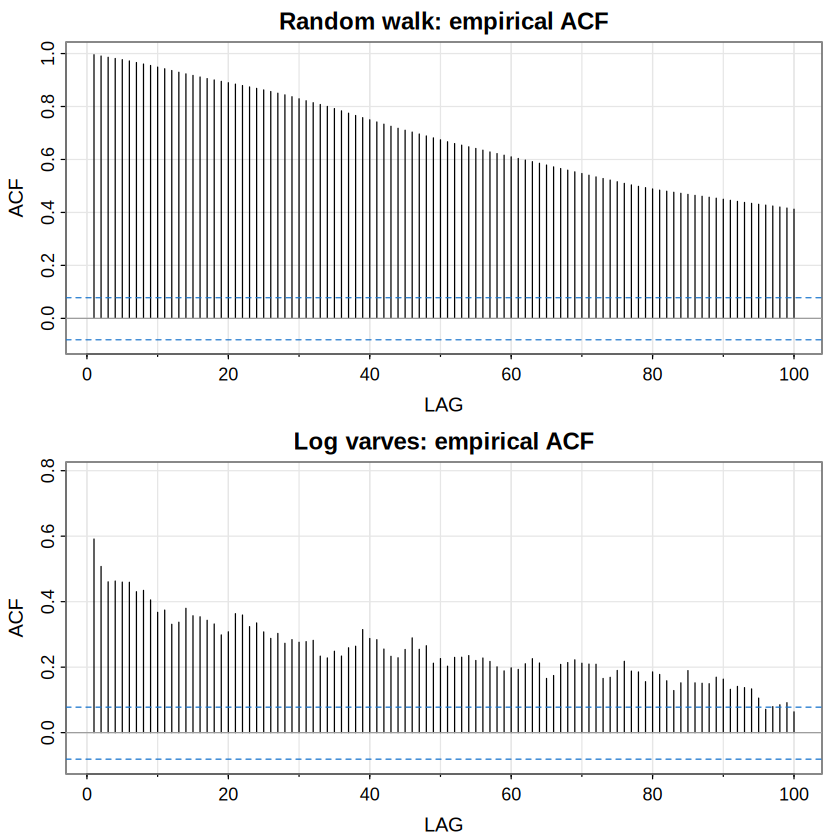

In [8]:
library(tseries)
set.seed(102)
rw = cumsum(rnorm(634))
par(mfrow=c(2,1))
acf1(rw, 100, main="Random walk: empirical ACF")
acf1(log(varve), 100, main="Log varves: empirical ACF")
par(mfrow=c(1,1))
cat("DF (0 augmenting lags):
")
print(adf.test(log(varve), k=0))
cat("ADF (default augmenting lags):
")
print(adf.test(log(varve)))
cat("Phillips-Perron:
")
print(pp.test(log(varve)))

**Interpretation.** A slowly decaying *sample* ACF can result from unit-root behavior or stationary long memory. In contrast to a stationary process, a random walk has no time-invariant population ACF, although `acf1()` still produces a finite-sample diagnostic.

For each unit-root test, report the observed statistic, chosen augmentation/truncation lag, and p-value. Rejection means the particular **unit-root null** is not supported under the test assumptions; it does **not** establish short memory or identify the best model. If the zero-lag DF and default-lag ADF tests differ, investigate residual dependence and sensitivity to lag selection.

## 8.3 Long memory and fractional differencing

For stationary ARMA processes, autocorrelations typically decay exponentially. **Long-memory** processes instead have slowly decaying dependence. A fractionally integrated noise model is

$$ (1-B)^d(x_t-\mu)=w_t,\qquad -\tfrac12<d<\tfrac12,$$

where $B x_t=x_{t-1}$ is the backshift operator. For $0<d<0.5$ the process has persistent long-range dependence; for $-0.5<d<0$ it is **antipersistent**. The model can be generalized to ARFIMA$(p,d,q)$:

$$\phi(B)(1-B)^d(x_t-\mu)=\theta(B)w_t.$$

A characteristic slow ACF decay is $\rho(h)\sim C h^{2d-1}$ for large lag $h$ and positive constant $C$ when $0<d<0.5$. This is slower than geometric decay.

### Fractional-difference coefficients and manual recursion

$$\pi_0(d)=1,\qquad \pi_{j+1}(d)=\frac{j-d}{j+1}\pi_j(d).$$

For $d=0.373$, $\pi_1=-0.373$ and

$$\pi_2=\frac{1-0.373}{2}(-0.373)\approx-0.11694.$$

The $\pi_j$ coefficients multiply past observations to form fractional differences; they are **not** a conventional AR coefficient vector. With $d>0$, the first coefficient is negative. Fractional *integration* coefficients $\psi_j$ follow a separate, positive recursion.

First six fractional-difference coefficients:
[1]  1.000000 -0.372789 -0.116909 -0.063412 -0.041649 -0.030214


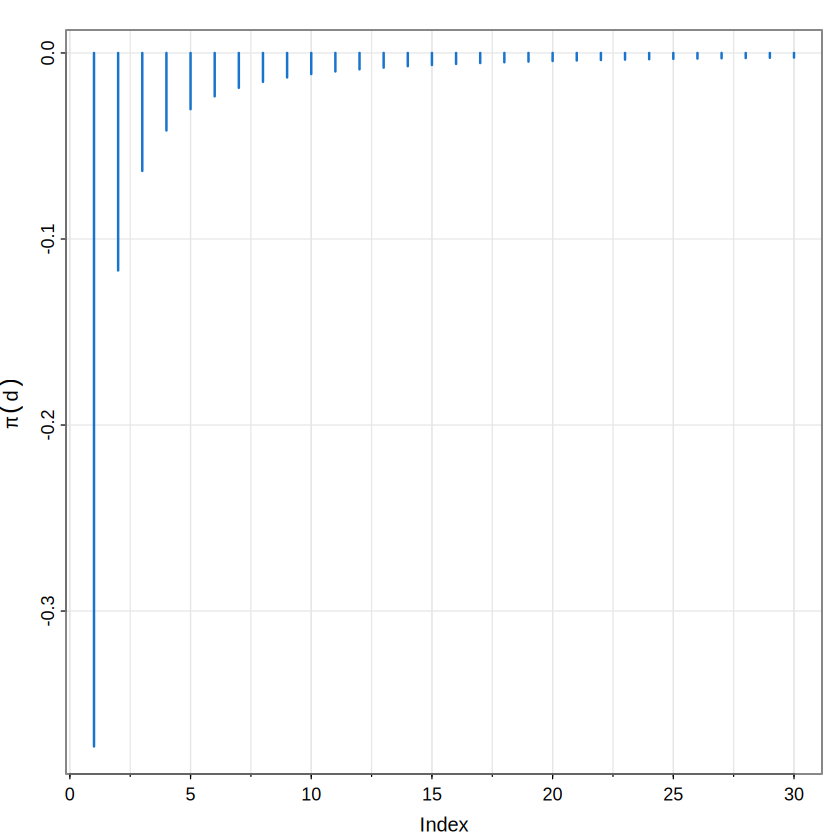

In [9]:
d = 0.3727893
p = c(1)
for (k in 1:30) p[k+1] = (k-1-d)*p[k]/k
cat("First six fractional-difference coefficients:
")
print(round(p[1:6], 6))
tsplot(1:30, p[-1], ylab=expression(pi(d)), lwd=2,
       xlab="Index", type="h", col="dodgerblue3")

**Interpretation of the fractional-difference weights.** The calculated coefficients begin with $\pi_0=1$, $\pi_1=-0.372789$, $\pi_2=-0.116909$, $\pi_3=-0.063412$, $\pi_4=-0.041649$, and $\pi_5=-0.030214$. The negative coefficients decay in magnitude rather than disappearing after a finite lag. These are fractional-differencing weights applied to past observations; they are **not** ordinary AR coefficients. The plot shows the gradual shrinkage of their magnitude, consistent with a long distributed-memory filter.

### ARFIMA estimation and residual comparison

The estimated fractional-difference parameter is the central diagnostic. For a value near $d=0.37$, the condition $0<d<0.5$ is consistent with stationary long memory. After estimation, compare the residual ACF with that of a fitted ARIMA model: the goal is to see whether persistent dependence remains after modeling. Similar residual ACFs do not, by themselves, establish which model forecasts better.

Loading required package: ltsa

Note that the arfima package has new defaults starting with
1.4-0: type arfimachanges() for a list, as well as some other notes.
NOTE: some of these are quite important!


Attaching package: ‘arfima’


The following object is masked from ‘package:stats’:

    BIC




Note: only one starting point.  Only one mode can be found -- this is now the default behavior.
Beginning the fits with 1 starting values.




Call:
 
arfima(z = log(varve), order = c(0, 0, 0))


Mode 1 Coefficients:
             Estimate Std. Error Th. Std. Err. z-value   Pr(>|z|)    
d.f         0.3727893  0.0273459     0.0309661 13.6324 < 2.22e-16 ***
Fitted mean 3.0814142  0.2646507            NA 11.6433 < 2.22e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1
sigma^2 estimated as 0.230081; Log-likelihood = 466.028; AIC = -926.056; BIC = -912.699

Numerical Correlations of Coefficients:
            d.f   Fitted mean
d.f          1.00 -0.01      
Fitted mean -0.01  1.00      

Theoretical Correlations of Coefficients:
    d.f 
d.f 1.00

Expected Fisher Information Matrix of Coefficients:
    d.f 
d.f 1.64

<><><><><><><><><><><><><><>
 
Coefficients: 
         Estimate     SE  t.value p.value
ar1        0.2341 0.0518   4.5184  0.0000
ma1       -0.8871 0.0292 -30.4107  0.0000
constant  -0.0013 0.0028  -0.4618  0.6444

sigma^2 estimated as 0.228355 on 630 degrees of freedom 
 
AIC = 1.37546  AICc = 1.37552  BIC = 1.40358 
 


[1] -0.01  0.04 -0.02  0.02  0.02  0.04 -0.01  0.03  0.00 -0.06  0.00 -0.09
[13] -0.06  0.04 -0.02  0.00 -0.02 -0.01 -0.07 -0.06  0.06  0.05 -0.02  0.04
[25] -0.01 -0.04  0.02 -0.05  0.00 -0.02 -0.01  0.03 -0.07 -0.06 -0.01 -0.06

[1] -0.03 -0.01 -0.04  0.02  0.04  0.06  0.01  0.06  0.03 -0.02  0.04 -0.05
[13] -0.03  0.08  0.02  0.03  0.02  0.02 -0.05 -0.03  0.09  0.07  0.00  0.06
[25]  0.01 -0.02  0.05 -0.02  0.02  0.01  0.02  0.06 -0.04 -0.04  0.02 -0.04

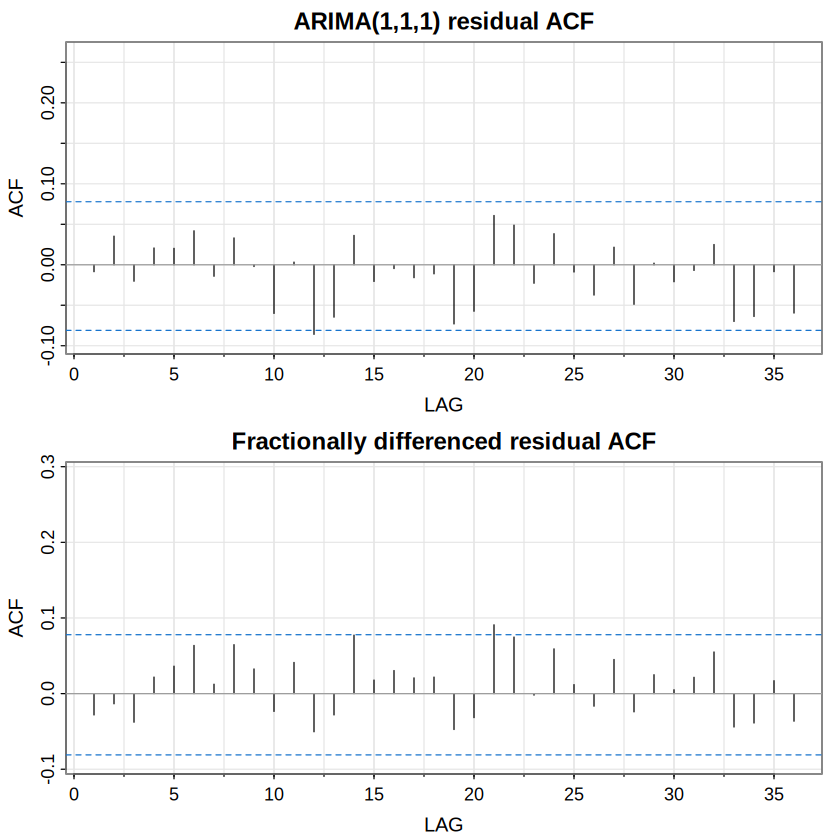

In [10]:
library(arfima)
varve_fd = arfima(log(varve), order=c(0,0,0))
summary(varve_fd)
innov = resid(varve_fd)[[1]]
varve_arima = sarima(log(varve), 1,1,1, details=FALSE)
par(mfrow=c(2,1))
acf1(resid(varve_arima$fit), main="ARIMA(1,1,1) residual ACF")
acf1(innov, main="Fractionally differenced residual ACF")
par(mfrow=c(1,1))

**Forecasting fractional noise.** If $\pi_j$ are the fractional-difference coefficients, the truncated forecast is

$$\widehat x_{n+m\mid n}-\mu=-\sum_{j=1}^{n+m-1}\pi_j(d)\,\bigl(\widehat x_{n+m-j\mid n}-\mu\bigr),$$

where already observed past values are substituted when $n+m-j\le n$. Its approximate mean squared prediction error is

$$\operatorname{MSPE}(m)\approx\sigma_w^2\sum_{j=0}^{m-1}\psi_j^2(d),\quad \psi_0=1,\quad \psi_{j+1}=\frac{j+d}{j+1}\psi_j.$$

These formulas make clear why forecast uncertainty must incorporate the accumulation of many slowly decaying shock weights.

  horizon root_MSPE
1       1   0.47929
2       2   0.51151
3       5   0.54109
4      10   0.55748
5      20   0.57051


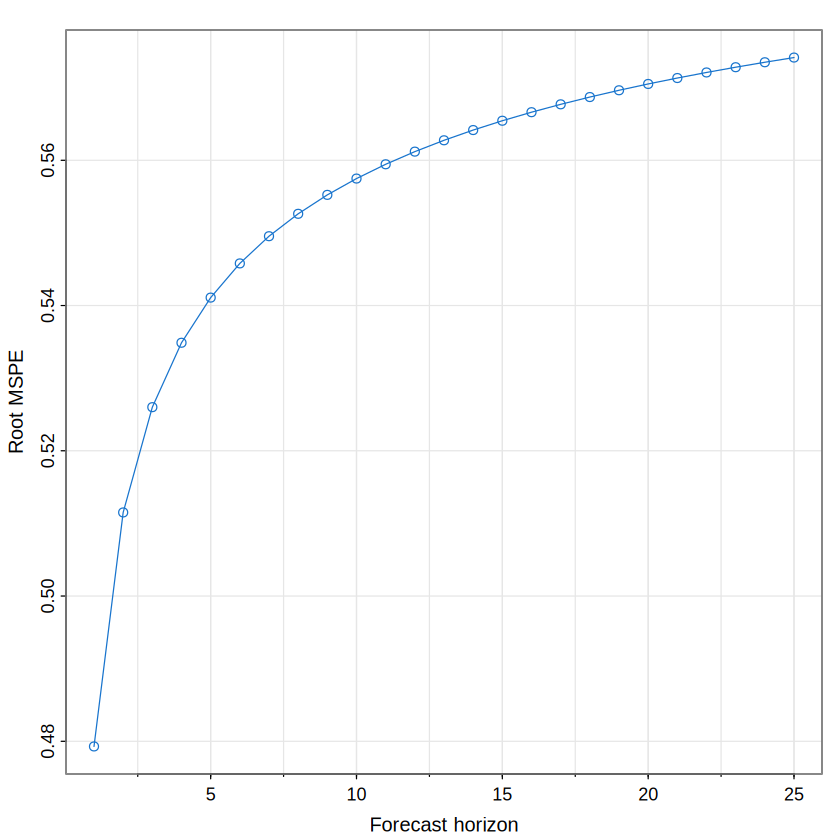

In [11]:
d = 0.3727893
psi = numeric(25)
psi[1] = 1
for (j in 1:24) psi[j+1] = (j-1+d)/j*psi[j]
sigma2 = 0.229718
mspe = sigma2*cumsum(psi^2)
print(data.frame(horizon=c(1,2,5,10,20),
                 root_MSPE=round(sqrt(mspe[c(1,2,5,10,20)]), 5)))
tsplot(1:25, sqrt(mspe), xlab="Forecast horizon", ylab="Root MSPE",
       col="dodgerblue3", type="o")

**Interpretation of forecast uncertainty.** The computed root-MSPE increases from **0.47929** at horizon 1 to **0.51151** at horizon 2, **0.54109** at horizon 5, **0.55748** at horizon 10 and **0.57051** at horizon 20. Longer horizons accumulate more innovation uncertainty, with diminishing additional increments in this example. These are **model-based theoretical calculations** using $d=0.3727893$ and a specified innovation variance; they are not measured out-of-sample forecasting errors.

## 8.4 State-space models and Kalman estimation

A **state-space model** separates an unobserved (*latent*) state $x_t$ from noisy observations $y_t$:

$$x_t=\alpha+\phi x_{t-1}+w_t,\quad w_t\sim N(0,\sigma_w^2),$$
$$y_t=Ax_t+v_t,\quad v_t\sim N(0,\sigma_v^2).$$

Here $\phi$ controls state persistence, $\alpha$ controls state drift, $A$ maps state to measurement, and $\sigma_w,\sigma_v$ control process and measurement noise. The initial state has mean $\mu_0$ and variance $P_0$.

- **Prediction:** estimate $x_t$ using measurements through $t-1$.
- **Filtering:** estimate $x_t$ using measurements through $t$.
- **Smoothing:** estimate an earlier $x_t$ using the complete data through $n$.

They are distinct information sets and therefore have different uncertainty.

### Scalar Kalman filter

For prior mean $a_t$ and variance $R_t$,

$$a_t=\alpha+\phi\widehat x_{t-1\mid t-1},\quad R_t=\phi^2P_{t-1\mid t-1}+\sigma_w^2.$$

The **innovation** is $e_t=y_t-Aa_t$ with variance $F_t=A^2R_t+\sigma_v^2$. The Kalman gain and updates are

$$K_t=\frac{R_tA}{F_t},\qquad \widehat x_{t\mid t}=a_t+K_te_t,$$
$$P_{t\mid t}=(1-K_tA)R_t.$$

**Worked update.** If $a_t=0.50$, $R_t=0.04$, $A=1$, $\sigma_v^2=0.09$, and $y_t=0.80$, then

$$K_t=\frac{0.04}{0.13}\approx0.30769,\quad \widehat x_{t\mid t}=0.50+0.30769(0.30)\approx0.59231,$$
$$P_{t\mid t}\approx(1-0.30769)(0.04)=0.02769.$$

The filtered state moves toward the observation by about 31% of the innovation, while its variance decreases.

In [12]:
a = 0.50; R = 0.04; A = 1; sigv2 = 0.09; y = 0.80
F = A^2*R + sigv2
K = R*A/F
xf = a + K*(y-A*a)
Pf = (1-K*A)*R
c(innovation=y-A*a, innovation_variance=F,
  Kalman_gain=K, filtered_state=xf, filtered_variance=Pf)

innovation innovation_variance         Kalman_gain      filtered_state 
          0.3000000           0.1300000           0.3076923           0.5923077 
  filtered_variance 
          0.0276923

The **Rauch–Tung–Striebel** backward smoother uses

$$C_t=\frac{\phi P_{t\mid t}}{P_{t+1\mid t}},\qquad \widehat x_{t\mid n}=\widehat x_{t\mid t}+C_t(\widehat x_{t+1\mid n}-\widehat x_{t+1\mid t}),$$
$$P_{t\mid n}=P_{t\mid t}+C_t^2(P_{t+1\mid n}-P_{t+1\mid t}).$$

For Gaussian innovations the log likelihood is built from $e_t^2/F_t$ and $\log F_t$. This allows the state-space parameters to be estimated using numerical optimization.

### Global temperature: state smoothing

The model regards annual temperature anomalies as measurements of an underlying persistent state. In `ssm()`, `Xs`/`Ps` are the smoothed state and variance, while `Xf`/`Pf` and `Xp`/`Pp` are filtered and predicted quantities. The plotted $\pm2\sqrt{P_{t\mid n}}$ ribbon describes uncertainty in the **latent state** under the fitted model; it does not represent a full prediction interval for new noisy measurements.

initial  value 548.852944 
iter   2 value 183.541591
iter   3 value 165.210632
iter   4 value 158.150038
iter   5 value 157.801755
iter   6 value 157.406192
iter   7 value 156.577268
iter   8 value 154.653522
iter   9 value 125.875639
iter  10 value 98.384838
iter  11 value 42.398673
iter  12 value 33.759156
iter  13 value 33.460241
iter  14 value 32.928640
iter  15 value 29.198053
iter  16 value 29.065980
iter  17 value 28.981839
iter  18 value 28.955042
iter  19 value 28.933848
iter  20 value 28.923359
iter  21 value 28.921539
iter  22 value 28.914760
iter  23 value 19.854698
iter  24 value 18.953562
iter  25 value -7.849852
iter  26 value -33.701537
iter  27 value -56.871600
iter  28 value -64.116913
iter  29 value -72.328903
iter  30 value -88.664957
iter  31 value -95.938648
iter  32 value -98.360087
iter  33 value -99.801335
iter  34 value -101.621427
iter  35 value -103.772801
iter  36 value -104.733601
iter  37 value -106.738351
iter  38 value -112.179284
iter  39 value -112.79

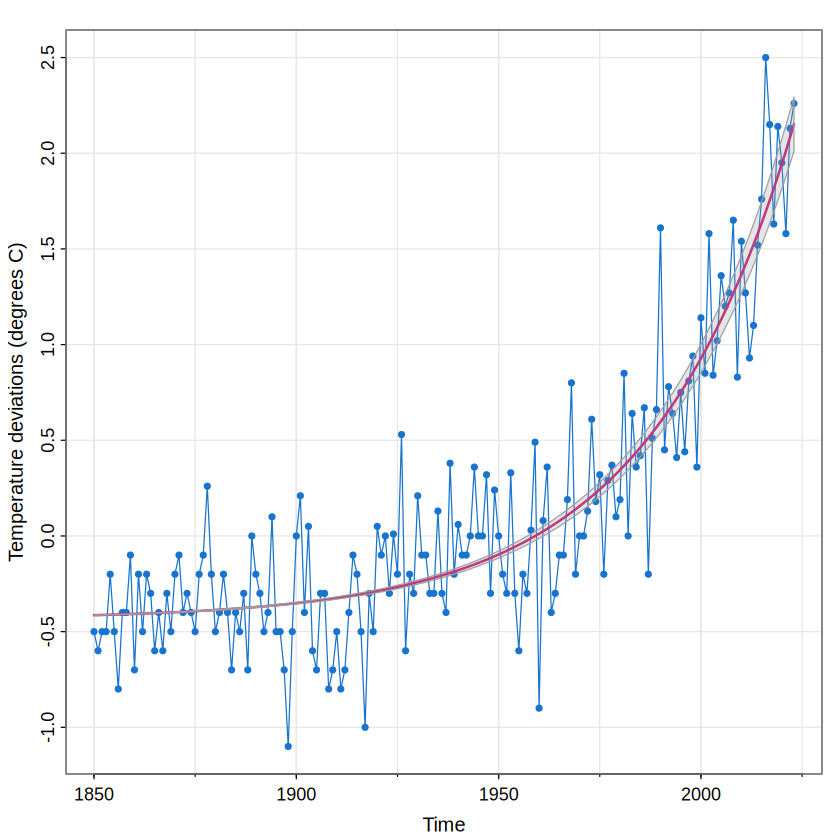

In [13]:
u = ssm(gtemp_land, A=1, alpha=.01, phi=1, sigw=.01, sigv=.1)
print(u)
tsplot(gtemp_land, col="dodgerblue3", type="o", pch=20,
       ylab="Temperature deviations (degrees C)")
lines(u$Xs, col=6, lwd=2)
xx = c(time(u$Xs), rev(time(u$Xs)))
yy = c(u$Xs-2*sqrt(u$Ps), rev(u$Xs+2*sqrt(u$Ps)))
polygon(xx, yy, border=8, col=gray(.6, alpha=.25))

**Interpretation.** The Kalman smoother tracks a latent temperature-anomaly signal, while the observations contain measurement and short-term variability. The output should be used to distinguish estimated state dynamics from measurement noise. The model's conditional error ribbon reflects uncertainty **under the fitted state-space assumptions**; it does not quantify structural climate uncertainty. The optimizer output and parameter estimates should be checked for convergence before using the smoother for inference. A near-unit or slightly larger-than-unit estimated $\phi$ implies high persistence; without an imposed stationarity restriction it should not automatically be interpreted as a stable causal AR(1).

## 8.5 Cross-correlation and prewhitening

If both input and output are autocorrelated, their raw cross-correlation may reflect shared persistence or common periodicity. **Prewhitening** first applies a fitted filter to one series so that its residuals are approximately white noise; the *same* filter is applied to the second series.

For an ARIMA model $\phi(B)(1-B)^d x_t=\theta(B)w_t$, its whitening filter is $\pi(B)=\theta(B)^{-1}\phi(B)(1-B)^d$. Applying $\pi(B)$ to $y_t$ creates a comparable filtered output. Only after aligning the transformed observations should their CCF be examined.

For a simple ARIMA$(1,1,0)$ with coefficient $\phi$, the filter is $(1-\phi B)(1-B)$.

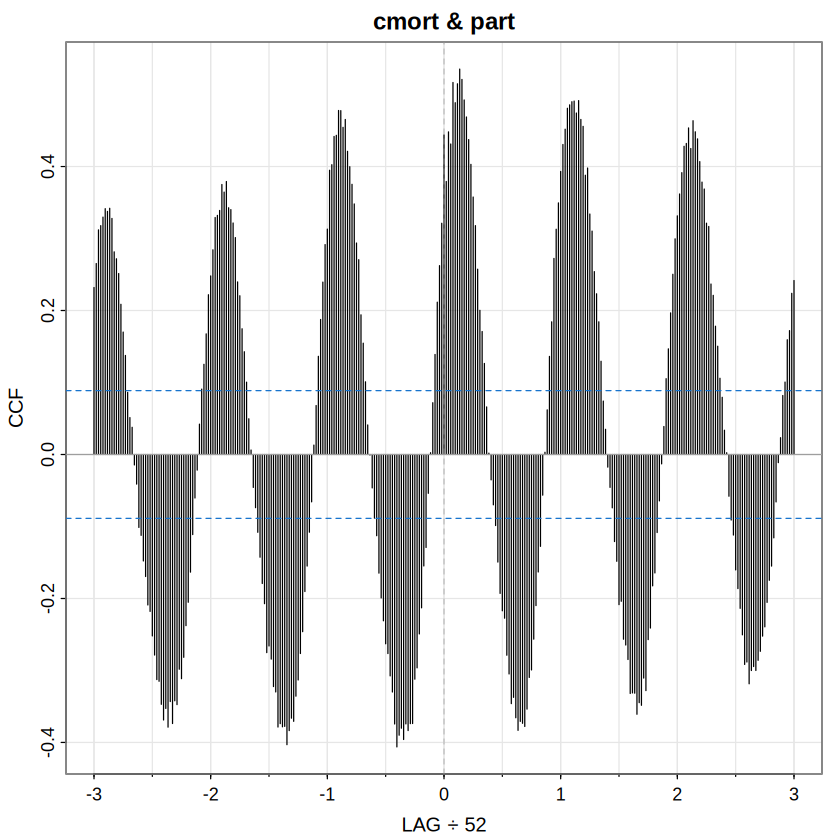

ACF,-0.51,0.21,-0.13,0.06,-0.02,-0.01,0.02,-0.09,0.12,-0.10,⋯,-0.02,-0.01,0.01,0.00,0.06,-0.03,0.00,0.03,-0.02,0.04
PACF,-0.51,-0.07,-0.07,-0.03,0.01,-0.01,0.02,-0.09,0.04,-0.01,⋯,0.02,0.01,0.03,-0.02,0.09,0.01,0.01,0.03,0.00,0.00


<><><><><><><><><><><><><><>
 
Coefficients: 
    Estimate     SE  t.value p.value
ar1  -0.5064 0.0383 -13.2224       0

sigma^2 estimated as 33.8106 on 506 degrees of freedom 
 
AIC = 6.36712  AICc = 6.36714  BIC = 6.3838 
 


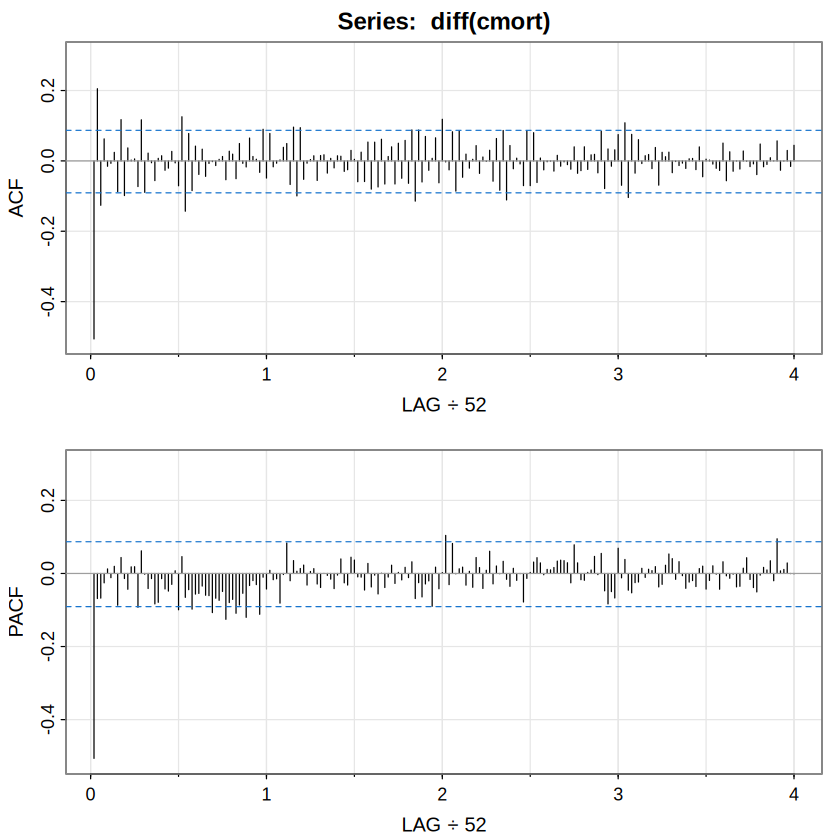

Whitening AR(1) coefficient: -0.506358 
Number of aligned observations: 507 


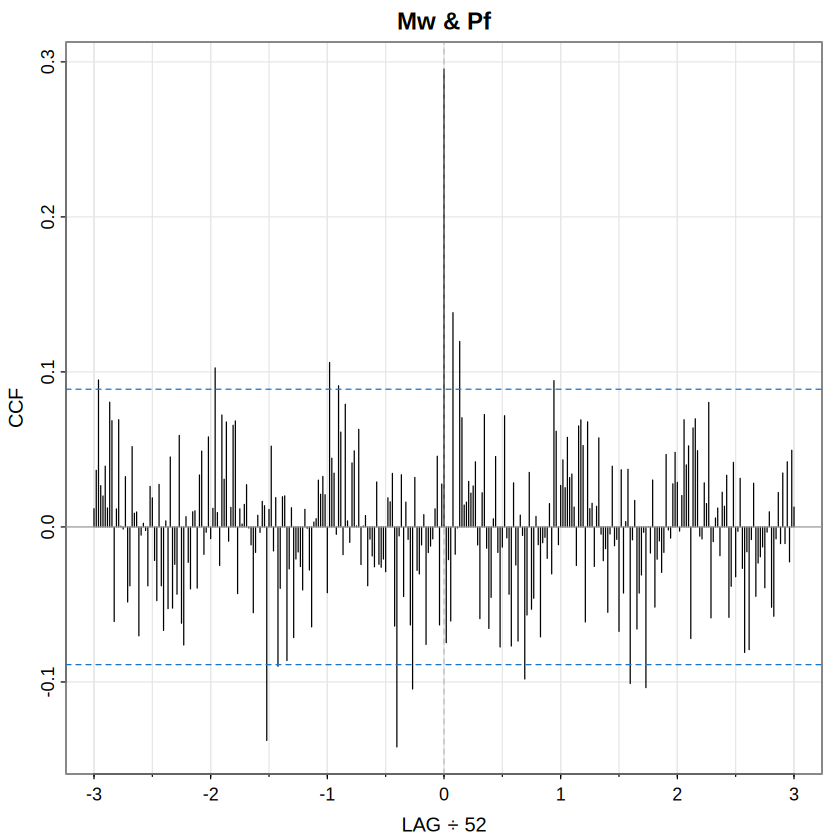

In [14]:
ccf2(cmort, part)
acf2(diff(cmort))
u = sarima(cmort, 1,1,0, no.constant=TRUE, details=FALSE)
cmortw = resid(u$fit)
phi = as.numeric(u$fit$coef["ar1"])
partf = stats::filter(diff(part), filter=c(1,-phi), sides=1)
both = ts.intersect(cmortw, partf)
Mw = both[,1]
Pf = both[,2]
ccf2(Mw, Pf)
cat("Whitening AR(1) coefficient:", phi, "\n")
cat("Number of aligned observations:", nrow(both), "\n")


**Interpretation of the executed prewhitening.** The fitted AR coefficient for differenced mortality is $\widehat\phi=-0.506358$, so the matching transformation for differenced pollution is $1-\widehat\phi B=1+0.506358B$. The cell aligns **507 observations** before computing the transformed CCF. A prominent correlation around lag zero indicates a contemporaneous association at this sampling resolution; it does not establish direction of causation. The raw and filtered CCFs answer different questions, because the latter reduces serial dependence that can create misleading broad cross-correlation patterns. Check the residual ACF of the whitened mortality series before interpreting nominal CCF significance bands.

## 8.6 Bootstrap inference for autoregressive models

A large-sample AR(1) interval uses the approximate variance

$$\operatorname{Var}(\widehat\phi)\approx\frac{1-\phi^2}{n}.$$

Near $|\phi|=1$, the finite-sample distribution can be skewed, and a normal interval may perform poorly. A **residual bootstrap** repeatedly resamples fitted innovations with replacement, generates new series using the fitted AR model, and refits the parameter. Its percentiles approximate uncertainty due to sampling under the fitted model.

For Laplace innovations with location zero and scale $b=2$,

$$f(w)=\frac{1}{2b}e^{-|w|/b},\quad E(w)=0,\quad \operatorname{Var}(w)=2b^2=8.$$

Laplace innovations have heavier tails than Gaussian innovations with the same variance.

               mean                 phi innovation_variance 
          45.245685            0.959901            7.880220 


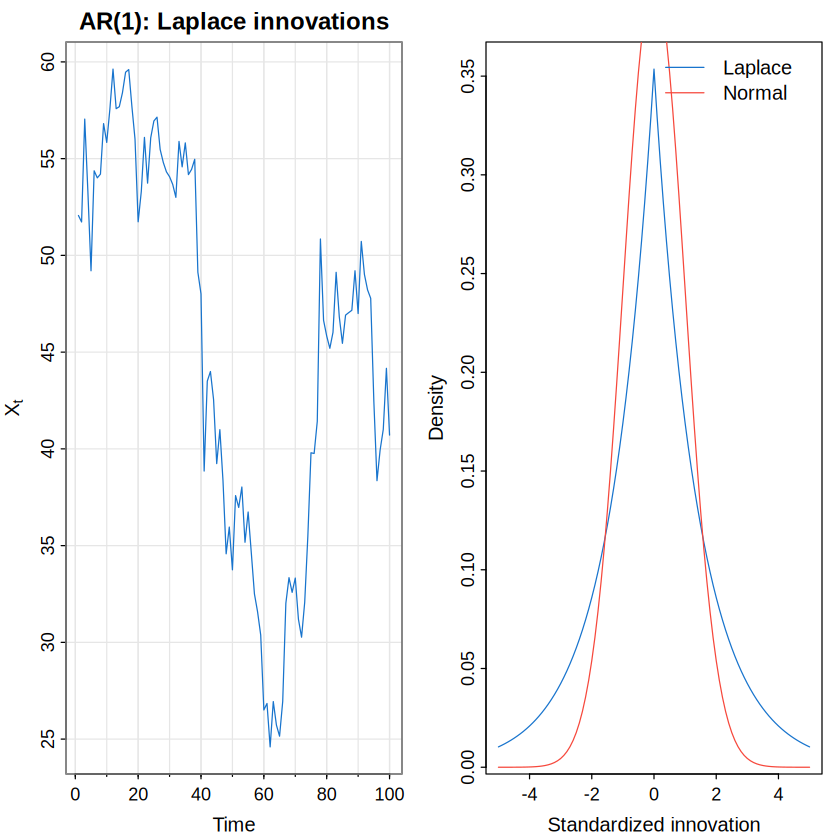

In [15]:
set.seed(101010)
e = rexp(150, rate=.5)
u = runif(150,-1,1)
de = e*sign(u)
dex = 50 + arima.sim(n=100, list(ar=.95), innov=de, n.start=50)
fit = ar.yw(dex, order=1)
print(c(mean=fit$x.mean, phi=fit$ar, innovation_variance=fit$var.pred))
par(mfrow=c(1,2))
tsplot(dex, col=4, ylab=expression(X[t]), main="AR(1): Laplace innovations")
f = function(x) {.5*dexp(abs(x), rate=1/sqrt(2))}
curve(f, -5,5, col=4, ylab="Density", xlab="Standardized innovation")
curve(dnorm(x), add=TRUE, col=2)
legend("topright", legend=c("Laplace", "Normal"), col=c(4,2), lty=1, bty="n")
par(mfrow=c(1,1))

The theoretical model uses $\mu=50$, $\phi=0.95$, and innovation variance 8; the fitted values need not equal them for a 100-point random sample. Compare fitted mean and AR coefficient with the generating parameters. The density plot compares *standardized* Laplace and standard normal densities; the Laplace distribution is more sharply peaked at zero and has heavier tails.

### Monte Carlo sampling distribution and residual bootstrap

The Monte Carlo experiment below assumes the *true* data-generating process is known, while the bootstrap uses only fitted parameters and empirical residuals. They answer different questions. Percentile bootstrap limits are not guaranteed to have exact coverage, especially close to the stationarity boundary.

In [16]:
set.seed(111)
phi_yw = numeric(1000)
for (i in 1:1000) {
  e = rexp(150, rate=.5)
  sgn = sign(runif(150,-1,1))
  x = 50 + arima.sim(n=100, list(ar=.95), innov=e*sgn, n.start=50)
  phi_yw[i] = ar.yw(x, order=1)$ar
}
set.seed(666)
fit = ar.yw(dex, order=1)
m = fit$x.mean
phi = as.numeric(fit$ar)
resids = as.numeric(fit$resid[-1])
nboot = 500
phi_star_yw = numeric(nboot)
for (i in 1:nboot) {
  resid_star = sample(resids, replace=TRUE)
  x_star = as.numeric(dex)
  for (t in 1:99) x_star[t+1] = m + phi*(x_star[t]-m) + resid_star[t]
  phi_star_yw[i] = ar.yw(x_star, order=1)$ar
}
alpha = .025
normal_se = sqrt((1-phi^2)/length(dex))
ci = rbind(
  bootstrap=quantile(phi_star_yw, c(alpha,1-alpha)),
  Monte_Carlo=quantile(phi_yw, c(alpha,1-alpha)),
  normal_approx=phi + c(-1,1)*qnorm(1-alpha)*normal_se
)
print(ci)
cat("Fitted phi:", phi, "; estimated normal SE:", normal_se, "\n")

                  2.5%    97.5%
bootstrap     0.785799 0.961511
Monte_Carlo   0.766478 0.960667
normal_approx 0.904956 1.014847
Fitted phi: 0.959901 ; estimated normal SE: 0.0280338 


**Interpretation of the executed confidence intervals.** The residual-bootstrap percentile interval is **[0.785799, 0.961511]**, close to the Monte Carlo sampling interval **[0.766478, 0.960667]** generated from the known simulation model. The asymptotic normal approximation is **[0.904956, 1.014847]**, notably narrower on the lower side and extending beyond the stationary AR(1) parameter boundary of 1. This illustrates the skewed finite-sample behavior of a persistence estimator near the boundary. Importantly, the Monte Carlo interval here is the empirical distribution of the *estimator* across simulations, not by itself a confidence interval constructed for the unknown true parameter. Likewise the simple bootstrap percentile interval is a practical approximation, not a proof of nominal coverage.

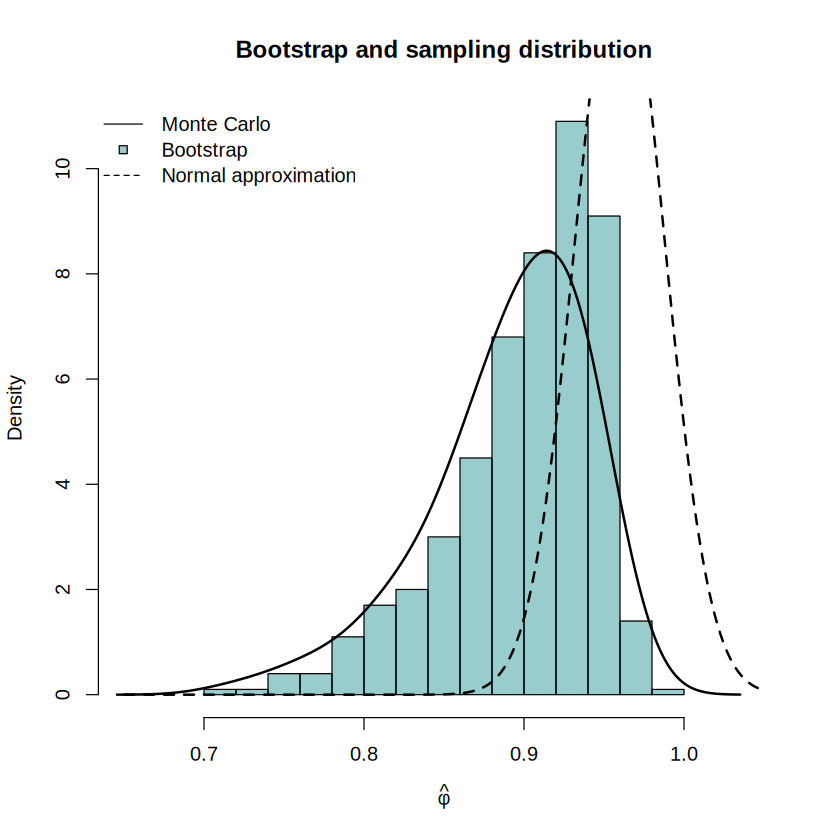

In [17]:
culer = rgb(0,.5,.5,.4)
hist(phi_star_yw, 15, main="Bootstrap and sampling distribution", prob=TRUE,
     xlim=c(.65,1.05), col=culer, xlab=expression(hat(phi)))
lines(density(phi_yw, bw=.02), lwd=2)
u = seq(.65,1.05,by=.001)
lines(u, dnorm(u, mean=phi, sd=normal_se), lty=2, lwd=2)
legend("topleft", legend=c("Monte Carlo", "Bootstrap", "Normal approximation"),
       lty=c(1,NA,2), pch=c(NA,22,NA), pt.bg=c(NA,culer,NA),
       col=c(1,1,1), bty="n")

A skewed sampling distribution is especially important when estimated persistence is near 1. Compare the histogram location and spread with the simulated Monte Carlo density, rather than describing the bootstrap as *exactly* reproducing the true distribution. The normal curve is a large-sample benchmark and may have a misleading tail shape.

## 8.7 Threshold autoregressive models (SETAR)

A **regime** is a subset of observations governed by a different autoregressive relationship. A two-regime, self-exciting threshold autoregressive model is

$$x_t=\begin{cases}
\alpha^{(1)}+\sum_{j=1}^{p_1}\phi_j^{(1)}x_{t-j}+w_t^{(1)}, & x_{t-d}<r,\\
\alpha^{(2)}+\sum_{j=1}^{p_2}\phi_j^{(2)}x_{t-j}+w_t^{(2)}, & x_{t-d}\ge r.
\end{cases}$$

Here $r$ is the threshold, $d$ is the threshold delay, and $p_1,p_2$ are regime-specific AR orders. The model is **nonlinear in the state**, even though each regime uses an ordinary linear regression. Its usefulness depends on whether the regime-dependent dynamics are supported by the observed transitions.

### Influenza deaths: regimes and lag plot

The monthly `flu` series measures pneumonia-and-influenza deaths per 10,000 people. The first difference $x_t=\Delta\mathrm{flu}_t$ represents the month-to-month change in death rates. The lag plot compares $x_t$ (vertical) with $x_{t-1}$ (horizontal); the lowess curve helps detect departures from a single straight-line relationship. The exploratory threshold $r=0.05$ is measured in **changes in deaths per 10,000**, not in the original death rate.

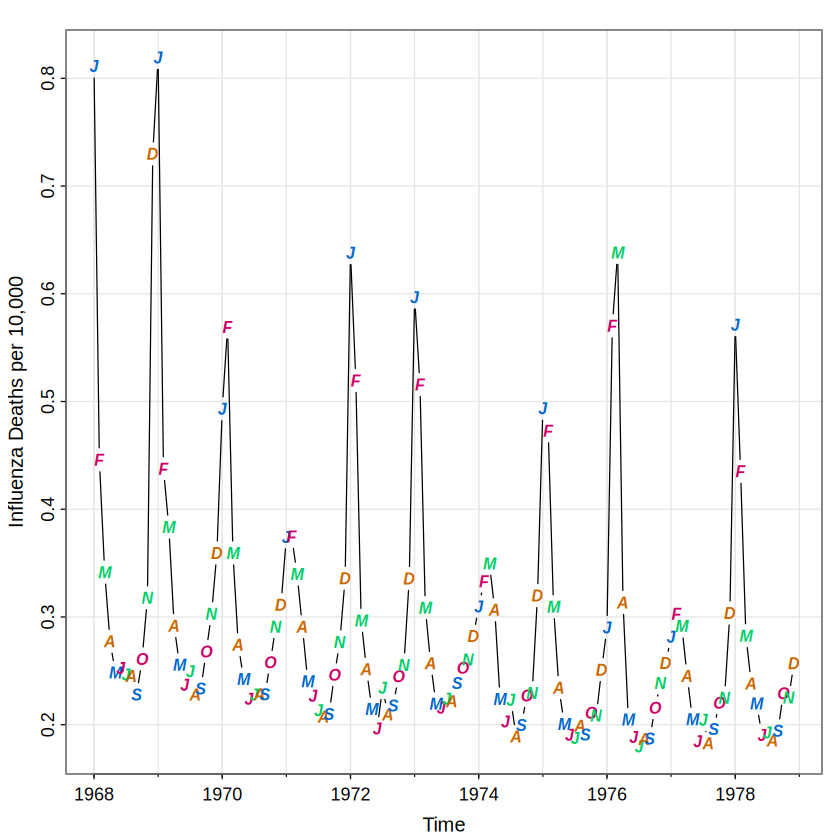

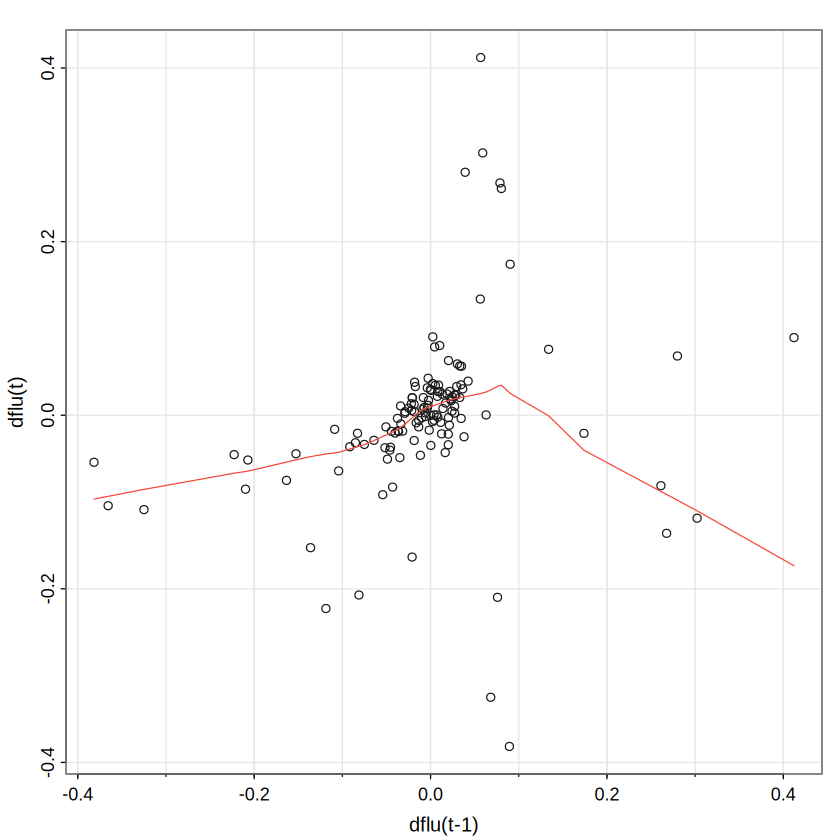

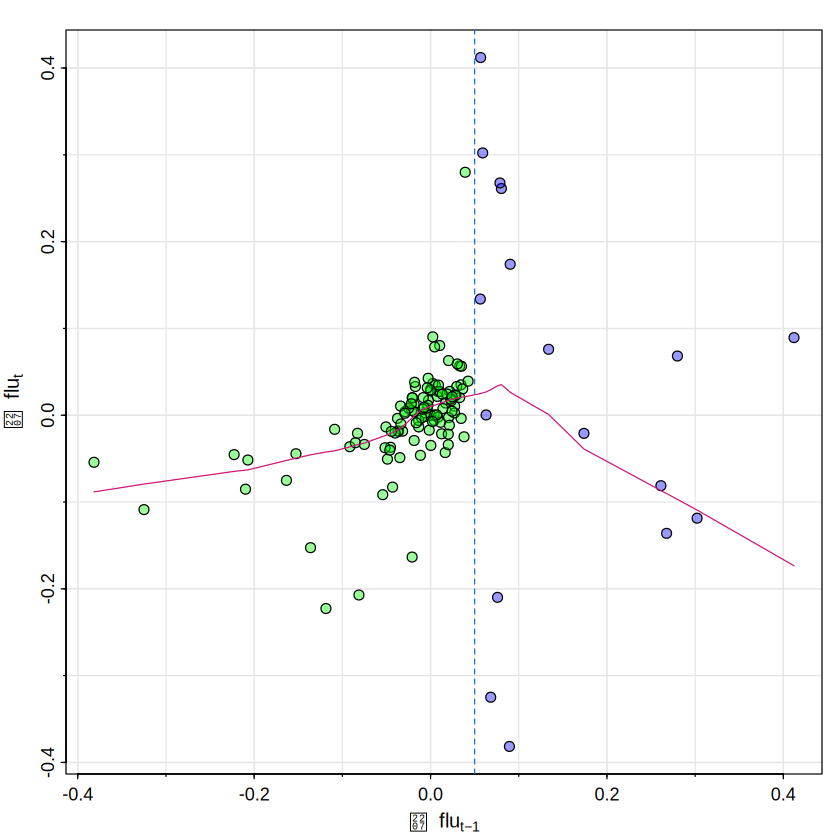

In [18]:
tsplot(flu, type="c", ylab="Influenza Deaths per 10,000")
Months = c("J","F","M","A","M","J","J","A","S","O","N","D")
culers = c(rgb(0,.4,.8), rgb(.8,0,.4), rgb(0,.8,.4), rgb(.8,.4,0))
points(flu, pch=Months, cex=.8, font=4, col=culers)

dflu = diff(flu)
lag1.plot(dflu, corr=FALSE)

# Colored lag plot showing the two regimes and the lowess fit
Z = ts.intersect(dflu, lag(dflu,-1), lag(dflu,-2),
                 lag(dflu,-3), lag(dflu,-4))
U = matrix(Z, ncol=5)
culer = c(rgb(0,1,0,.4), rgb(0,0,1,.4))
regime_col = ifelse(U[,2] < .05, culer[1], culer[2])
plot(U[,2], U[,1], panel.first=Grid(), pch=21, cex=1.1,
     bg=regime_col,
     xlab=expression(nabla~flu[t-1]),
     ylab=expression(nabla~flu[t]))
lines(lowess(U[,2], U[,1], f=2/3), col=6)
abline(v=.05, lty=2, col=4)


The changing steepness of the lowess curve indicates how the expected subsequent change varies with the previous change. A few large winter peaks should not, by themselves, dictate the number of regimes; compare residual behavior and prediction stability. The year-label patterns are descriptive, not evidence of a deterministic seasonal model.

The regime-colored scatterplot uses green for prior changes below $0.05$ and blue for changes at or above $0.05$; the fitted lowess curve is purple. The dashed blue vertical line identifies the threshold.

### Fit regime-specific AR(4) models

The design matrix contains an intercept and four past differences. A given observation is assigned to regime 1 when $x_{t-1}<0.05$, otherwise regime 2. The fitted conditional mean switches coefficients at this threshold. Standard errors may be especially large in regime 2 if relatively few observations exceed the threshold.

In [19]:
thrsh = .05
Z = ts.intersect(dflu, lag(dflu,-1), lag(dflu,-2),
                 lag(dflu,-3), lag(dflu,-4))
ind1 = ifelse(Z[,2] < thrsh, 1, NA)
ind2 = ifelse(Z[,2] < thrsh, NA, 1)
X1 = Z[,1]*ind1
X2 = Z[,1]*ind2
fit1 = lm(X1 ~ Z[,2:5])
fit2 = lm(X2 ~ Z[,2:5])
summary(fit1)
summary(fit2)
cat("Regime 1 observations:", sum(!is.na(X1)), "\n")
cat("Regime 2 observations:", sum(!is.na(X2)), "\n")


Call:
lm(formula = X1 ~ Z[, 2:5])

Residuals:
     Min       1Q   Median       3Q      Max 
-0.13312 -0.02049  0.00218  0.01667  0.26666 

Coefficients:
                      Estimate Std. Error t value Pr(>|t|)    
(Intercept)            0.00447    0.00489    0.91   0.3630    
Z[, 2:5]lag(dflu, -1)  0.50665    0.07832    6.47  3.2e-09 ***
Z[, 2:5]lag(dflu, -2) -0.20009    0.05657   -3.54   0.0006 ***
Z[, 2:5]lag(dflu, -3)  0.12105    0.05446    2.22   0.0284 *  
Z[, 2:5]lag(dflu, -4) -0.11094    0.04598   -2.41   0.0176 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.0458 on 105 degrees of freedom
  (17 observations deleted due to missingness)
Multiple R-squared:  0.376,	Adjusted R-squared:  0.353 
F-statistic: 15.8 on 4 and 105 DF,  p-value: 3.57e-10



Call:
lm(formula = X2 ~ Z[, 2:5])

Residuals:
     Min       1Q   Median       3Q      Max 
-0.08997 -0.03683 -0.00633  0.04077  0.12951 

Coefficients:
                      Estimate Std. Error t value Pr(>|t|)    
(Intercept)             0.4079     0.0467    8.73  1.5e-06 ***
Z[, 2:5]lag(dflu, -1)  -0.7483     0.1664   -4.50  0.00073 ***
Z[, 2:5]lag(dflu, -2)  -1.0323     0.2114   -4.88  0.00038 ***
Z[, 2:5]lag(dflu, -3)  -2.0450     1.0500   -1.95  0.07523 .  
Z[, 2:5]lag(dflu, -4)  -6.7118     1.2454   -5.39  0.00016 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.0721 on 12 degrees of freedom
  (110 observations deleted due to missingness)
Multiple R-squared:  0.921,	Adjusted R-squared:  0.894 
F-statistic: 34.8 on 4 and 12 DF,  p-value: 1.62e-06


Regime 1 observations: 110 
Regime 2 observations: 17 


**Interpretation of the regime fits.** With threshold $0.05$, the executed regression assigns **110 observations to regime 1** ($x_{t-1}<0.05$) and only **17 to regime 2** ($x_{t-1}\ge 0.05$). The second regime therefore has much less information for estimating five coefficients (intercept and four lag coefficients), so its individual estimates and predictive behavior can be unstable. A positive lag coefficient indicates persistence of the preceding change *conditional on the regime*; a negative coefficient indicates reversal. The intercept predicts the change when the four lags are zero—not the death rate itself.

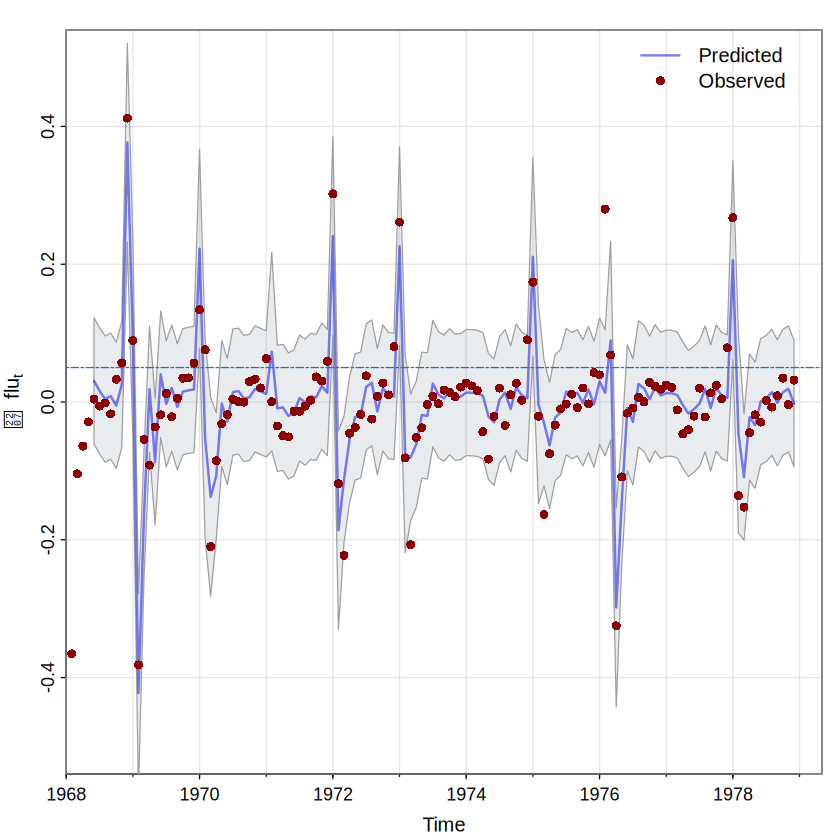

In [20]:
D = cbind(rep(1, nrow(Z)), Z[,2:5])
p1 = as.vector(D %*% coef(fit1))
p2 = as.vector(D %*% coef(fit2))
prd = ts(ifelse(Z[,2] < thrsh, p1, p2),
         start=start(Z), frequency=frequency(Z))
prde1 = sqrt(sum(resid(fit1)^2)/df.residual(fit1))
prde2 = sqrt(sum(resid(fit2)^2)/df.residual(fit2))
prde = ifelse(Z[,2] < thrsh, prde1, prde2)

# Draw shaded uncertainty first, then predicted line and observations.
tsplot(prd, type="n", ylim=c(-.5,.5),
       ylab=expression(nabla~flu[t]))
xx = c(time(prd), rev(time(prd)))
yy = c(as.numeric(prd)-2*prde, rev(as.numeric(prd)+2*prde))
polygon(xx, yy, border=8, col=rgb(.4,.5,.6,.15))
lines(prd, lwd=2, col=rgb(0,0,.9,.5))
abline(h=.05, col=4, lty=6)
points(dflu, pch=16, col="darkred")
legend("topright", legend=c("Predicted", "Observed"),
       lty=c(1,NA), lwd=c(2,NA), pch=c(NA,16),
       col=c(rgb(0,0,.9,.5), "darkred"), bty="n")


**Interpretation of the prediction plot.** The blue line is the in-sample fitted *one-month-ahead conditional mean of the change* in influenza mortality, not the mortality level. Dark-red points are observed changes. The gray band is an approximate $\pm2$ fitted regime-specific residual-standard-deviation band, **not a formally calibrated out-of-sample prediction interval**. The plot should be assessed particularly at abrupt epidemic spikes because the model can fit ordinary periods well and still miss extreme peaks. The shading is drawn before the observations so it does not hide the points or fitted line.

### Threshold selection with base R

Fit an AR(4) separately in each regime and search a specified threshold grid. The search minimizes within-sample SSE, so it is not equivalent to automatic `setar()` estimation and does not supply directly comparable package AIC/BIC statistics. Compare threshold, SSE, regime membership and coefficients, and examine residual autocorrelation before interpreting a numerical improvement.

In [21]:
# Threshold autoregressive model using base R (no tsDyn needed)

df_lag = ts.intersect(
  dflu,
  lag(dflu, -1),
  lag(dflu, -2),
  lag(dflu, -3),
  lag(dflu, -4)
)

Z = as.matrix(df_lag)
colnames(Z) = c("y", "lag1", "lag2", "lag3", "lag4")

# Function to fit a two-regime SETAR(4) model
fit_setar = function(threshold) {

  regime1 = Z[, "lag1"] < threshold
  regime2 = !regime1

  fit1 = lm(y ~ lag1 + lag2 + lag3 + lag4,
            data=as.data.frame(Z[regime1, , drop=FALSE]))

  fit2 = lm(y ~ lag1 + lag2 + lag3 + lag4,
            data=as.data.frame(Z[regime2, , drop=FALSE]))

  predictions = numeric(nrow(Z))
  predictions[regime1] = fitted(fit1)
  predictions[regime2] = fitted(fit2)

  SSE = sum((Z[, "y"] - predictions)^2)

  list(
    threshold=threshold,
    regime1=fit1,
    regime2=fit2,
    SSE=SSE,
    predictions=predictions
  )
}

# Fixed threshold
u_fixed = fit_setar(.05)

# Search for the best threshold
thresholds = seq(.02, .08, by=.001)

models = lapply(thresholds, fit_setar)
SSE = sapply(models, function(model) model$SSE)

u_est = models[[which.min(SSE)]]

# Display results
cat("Fixed threshold:", u_fixed$threshold, "\n")
cat("Estimated threshold:", u_est$threshold, "\n")

cat("Fixed threshold SSE:", u_fixed$SSE, "\n")
cat("Estimated threshold SSE:", u_est$SSE, "\n")

summary(u_fixed$regime1)
summary(u_fixed$regime2)

summary(u_est$regime1)
summary(u_est$regime2)

Fixed threshold: 0.05 
Estimated threshold: 0.043 
Fixed threshold SSE: 0.28243 
Estimated threshold SSE: 0.28243 



Call:
lm(formula = y ~ lag1 + lag2 + lag3 + lag4, data = as.data.frame(Z[regime1, 
    , drop = FALSE]))

Residuals:
     Min       1Q   Median       3Q      Max 
-0.13312 -0.02049  0.00218  0.01667  0.26666 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  0.00447    0.00489    0.91   0.3630    
lag1         0.50665    0.07832    6.47  3.2e-09 ***
lag2        -0.20009    0.05657   -3.54   0.0006 ***
lag3         0.12105    0.05446    2.22   0.0284 *  
lag4        -0.11094    0.04598   -2.41   0.0176 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.0458 on 105 degrees of freedom
Multiple R-squared:  0.376,	Adjusted R-squared:  0.353 
F-statistic: 15.8 on 4 and 105 DF,  p-value: 3.57e-10



Call:
lm(formula = y ~ lag1 + lag2 + lag3 + lag4, data = as.data.frame(Z[regime2, 
    , drop = FALSE]))

Residuals:
     Min       1Q   Median       3Q      Max 
-0.08997 -0.03683 -0.00633  0.04077  0.12951 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   0.4079     0.0467    8.73  1.5e-06 ***
lag1         -0.7483     0.1664   -4.50  0.00073 ***
lag2         -1.0323     0.2114   -4.88  0.00038 ***
lag3         -2.0450     1.0500   -1.95  0.07523 .  
lag4         -6.7118     1.2454   -5.39  0.00016 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.0721 on 12 degrees of freedom
Multiple R-squared:  0.921,	Adjusted R-squared:  0.894 
F-statistic: 34.8 on 4 and 12 DF,  p-value: 1.62e-06



Call:
lm(formula = y ~ lag1 + lag2 + lag3 + lag4, data = as.data.frame(Z[regime1, 
    , drop = FALSE]))

Residuals:
     Min       1Q   Median       3Q      Max 
-0.13312 -0.02049  0.00218  0.01667  0.26666 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  0.00447    0.00489    0.91   0.3630    
lag1         0.50665    0.07832    6.47  3.2e-09 ***
lag2        -0.20009    0.05657   -3.54   0.0006 ***
lag3         0.12105    0.05446    2.22   0.0284 *  
lag4        -0.11094    0.04598   -2.41   0.0176 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.0458 on 105 degrees of freedom
Multiple R-squared:  0.376,	Adjusted R-squared:  0.353 
F-statistic: 15.8 on 4 and 105 DF,  p-value: 3.57e-10



Call:
lm(formula = y ~ lag1 + lag2 + lag3 + lag4, data = as.data.frame(Z[regime2, 
    , drop = FALSE]))

Residuals:
     Min       1Q   Median       3Q      Max 
-0.08997 -0.03683 -0.00633  0.04077  0.12951 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   0.4079     0.0467    8.73  1.5e-06 ***
lag1         -0.7483     0.1664   -4.50  0.00073 ***
lag2         -1.0323     0.2114   -4.88  0.00038 ***
lag3         -2.0450     1.0500   -1.95  0.07523 .  
lag4         -6.7118     1.2454   -5.39  0.00016 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.0721 on 12 degrees of freedom
Multiple R-squared:  0.921,	Adjusted R-squared:  0.894 
F-statistic: 34.8 on 4 and 12 DF,  p-value: 1.62e-06


### Residual checks and model limitations

The fixed-threshold fit ($0.05$) and grid-search estimate ($0.043$) both display an SSE of **0.28243** at the recorded precision. This does **not** establish that their fitted coefficients are identical or that the estimated threshold is uniquely determined; differences can be smaller than the printed precision, and neighboring thresholds may produce identical regime assignments. The subsequent fixed-threshold residual calculation reports an in-sample RMSE of **0.0471578** for one-step fitted changes. That is **not** a held-out forecast error. Inspect residual autocorrelation and regime-specific errors before claiming model adequacy. The smaller regime contains only 17 observations, so sensitivity to threshold selection is a concern.

Volatility models describe time-varying conditional variance; fractional integration describes slowly decaying dependence; state-space models estimate latent trajectories; prewhitening examines lead–lag relationships; bootstrap investigates estimator uncertainty; and SETAR allows regime-specific conditional means.

[1] -0.16  0.12 -0.12  0.00 -0.02 -0.13 -0.01 -0.11  0.05 -0.10  0.08  0.09
[13]  0.04  0.02 -0.06 -0.07 -0.03 -0.07 -0.03  0.04 -0.19  0.11

RMSE of fitted one-step changes: 0.0471578 


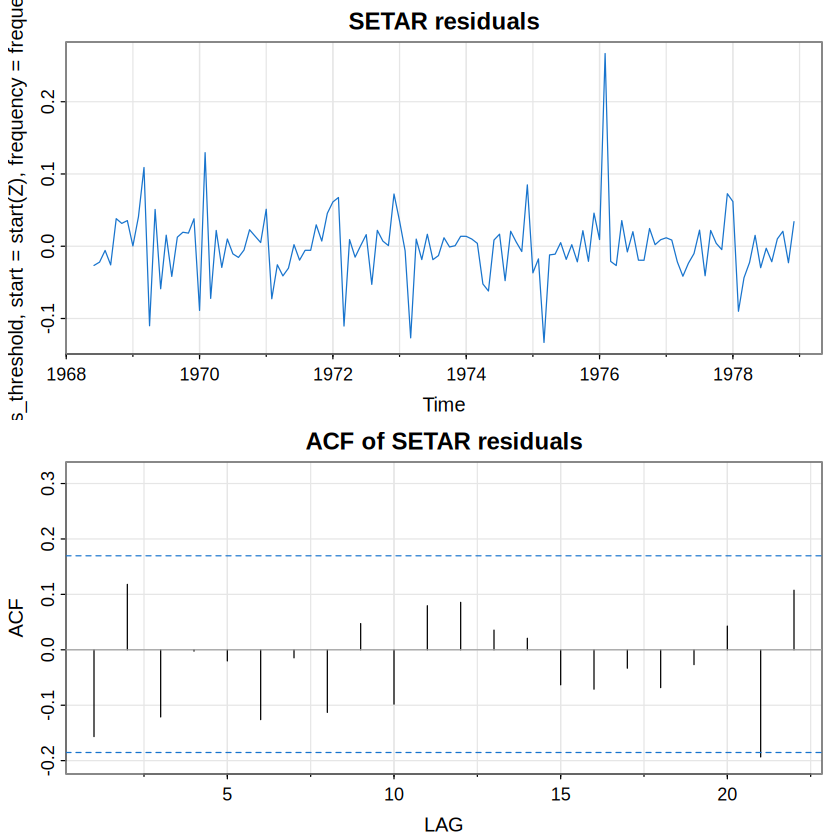

In [22]:
res_threshold = as.numeric(Z[,1]) - as.numeric(prd)
par(mfrow=c(2,1))
tsplot(ts(res_threshold, start=start(Z), frequency=frequency(Z)),
       main="SETAR residuals", col="dodgerblue3")
acf1(res_threshold, main="ACF of SETAR residuals")
par(mfrow=c(1,1))
cat("RMSE of fitted one-step changes:", sqrt(mean(res_threshold^2)), "\n")

## Reference

Shumway, R. H., & Stoffer, D. S. (2019). *Time Series: A Data Analysis Approach Using R*. Chapman & Hall/CRC.